# Follow-up checks

Notebook 03 found that users with many ratings were chosen far more often than chance. Here we check three things, using the results of `scripts/follow_up_checks.py` (run `python scripts/reproduce.py` first):

1. Does that advantage survive a fairer comparison with users who had a similar chance of being rated? (preferential attachment)
2. Is there more clustering than the degrees alone would give? (degree-preserving randomization)
3. How did the shape of the network change over the years?

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import networkx as nx
from IPython.display import display, Image

ROOT = Path('..')  # project folder
OUT = ROOT / 'outputs' / 'follow_up'

matched = pd.read_csv(OUT / 'matched_target_choice.csv')
rewired = pd.read_csv(OUT / 'degree_preserving_null.csv')
evolution = pd.read_csv(OUT / 'structural_evolution.csv')
meta = json.loads((OUT / 'metadata.json').read_text())

## 1. Compare with users who had a similar chance

A user who has been around longer, or who is very active, has more chances to be rated. So for each rating we now compare the recipient only with possible recipients in the **same two groups**:

- **tenure**: days since their first positive rating (under 90, 90–364, 365 or more);
- **recent activity**: positive ratings they gave or received in the previous 90 days (0, 1–2, 3–9, 10 or more).

Then we compute $R_k = O_k / E_k$ as in notebook 03. If BA's linear preferential attachment $\Pi(k) \propto k$ were the whole story, $R_k$ would still rise steadily with degree.

,prior_positive_in_degree,observed_target_events,matched_null_expected_events,observed_over_expected
0,0,601,156.234,3.847
1,1,3087,3346.705,0.922
2,2-3,3710,4797.392,0.773
3,4-7,4117,5486.153,0.750
4,8-15,4198,5158.026,0.814
5,16-31,3986,3623.942,1.100
6,32+,7294,4424.548,1.649


Ratings used: 26993
Share of ratings used: 99.48 %


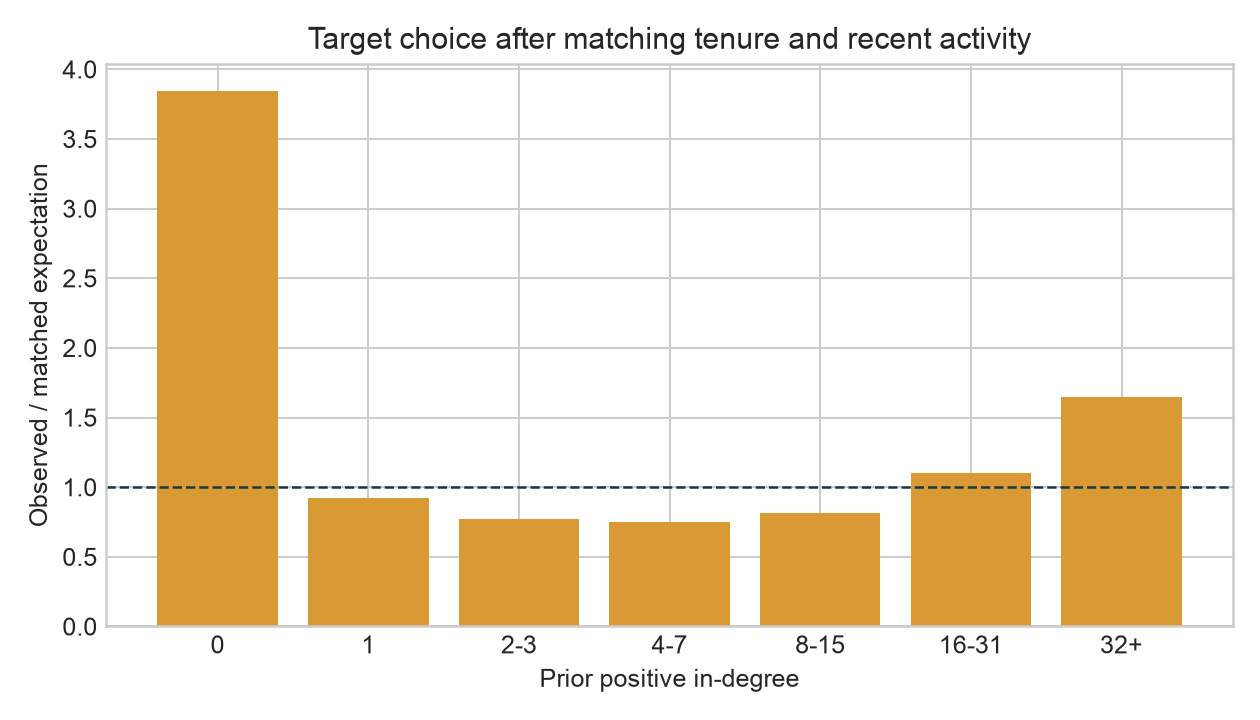

In [2]:
display(matched.round(3))
print('Ratings used:', meta['matched_choice']['matched_events'])
print('Share of ratings used:', round(100 * meta['matched_choice']['coverage_of_existing_target_events'], 2), '%')
Image(filename=str(OUT / 'matched_target_choice.png'))

For the 32+ group the ratio drops from 12.70 (notebook 03) to about 1.65. Most of the advantage of highly rated users disappears once we compare like with like, but they are still chosen somewhat more often. The 0 group is also high; notebook 05 shows this comes from users rating back someone who has just rated them.

### Work through one matched rating

An **invented** example. Seven users could receive the rating, and C gets it. C first appeared 40 days ago (under-90 group) and had 4 ratings in the last 90 days (3–9 group). We keep only users in both of C's groups: H has been around too long and I is too active, which leaves five users, including C.

In [3]:
candidates = pd.DataFrame([
    ('C', 2, 40, 4), ('D', 1, 50, 6), ('E', 3, 20, 5),
    ('F', 0, 10, 3), ('G', 1, 60, 4),
    ('H', 15, 400, 5), ('I', 8, 55, 10),
], columns=['user', 'ratings_received', 'tenure_days', 'activity_90_days'])

candidates['tenure_group'] = pd.cut(candidates['tenure_days'], [0, 90, 365, np.inf], right=False,
                                    labels=['under 90', '90-364', '365+'])
candidates['activity_group'] = pd.cut(candidates['activity_90_days'], [0, 1, 3, 10, np.inf], right=False,
                                      labels=['0', '1-2', '3-9', '10+'])
display(candidates)

c = candidates[candidates['user'] == 'C'].iloc[0]
same = candidates[(candidates['tenure_group'] == c['tenure_group']) &
                  (candidates['activity_group'] == c['activity_group'])]
display(same)

expected = same['ratings_received'].between(2, 3).mean()  # share of matched users in the 2-3 group
observed = 1 if 2 <= c['ratings_received'] <= 3 else 0
print('Expected count for the 2-3 group:', expected)
print('Observed / expected:', observed / expected)

,user,ratings_received,tenure_days,activity_90_days,tenure_group,activity_group
0,C,2,40,4,under 90,3-9
1,D,1,50,6,under 90,3-9
2,E,3,20,5,under 90,3-9
3,F,0,10,3,under 90,3-9
4,G,1,60,4,under 90,3-9
5,H,15,400,5,365+,3-9
6,I,8,55,10,under 90,10+


,user,ratings_received,tenure_days,activity_90_days,tenure_group,activity_group
0,C,2,40,4,under 90,3-9
1,D,1,50,6,under 90,3-9
2,E,3,20,5,under 90,3-9
3,F,0,10,3,under 90,3-9
4,G,1,60,4,under 90,3-9


Expected count for the 2-3 group: 0.4
Observed / expected: 2.5


Two of the five have received 2–3 ratings, so the expected count is $2/5 = 0.4$ and the ratio for this rating is $1/0.4 = 2.5$. The script adds these up over all ratings.

## 2. Degree-preserving randomization

To see whether the clustering is more than the degrees alone would give, we shuffle the network while keeping every user's degree: take two links A–B and C–D and swap their ends to A–D and C–B. This is the degree-preserving null model from the course. The script makes ten swaps per link and repeats this with eight seeds; we call each result a "rewire". It uses the undirected network.

,network,seed,transitivity,edges
0,observed,-1,0.0570,18591
1,degree_preserving_rewire,2026,0.0439,18591
2,degree_preserving_rewire,2027,0.0440,18591
3,degree_preserving_rewire,2028,0.0432,18591
4,degree_preserving_rewire,2029,0.0438,18591
5,degree_preserving_rewire,2030,0.0431,18591
6,degree_preserving_rewire,2031,0.0420,18591
7,degree_preserving_rewire,2032,0.0436,18591
8,degree_preserving_rewire,2033,0.0407,18591


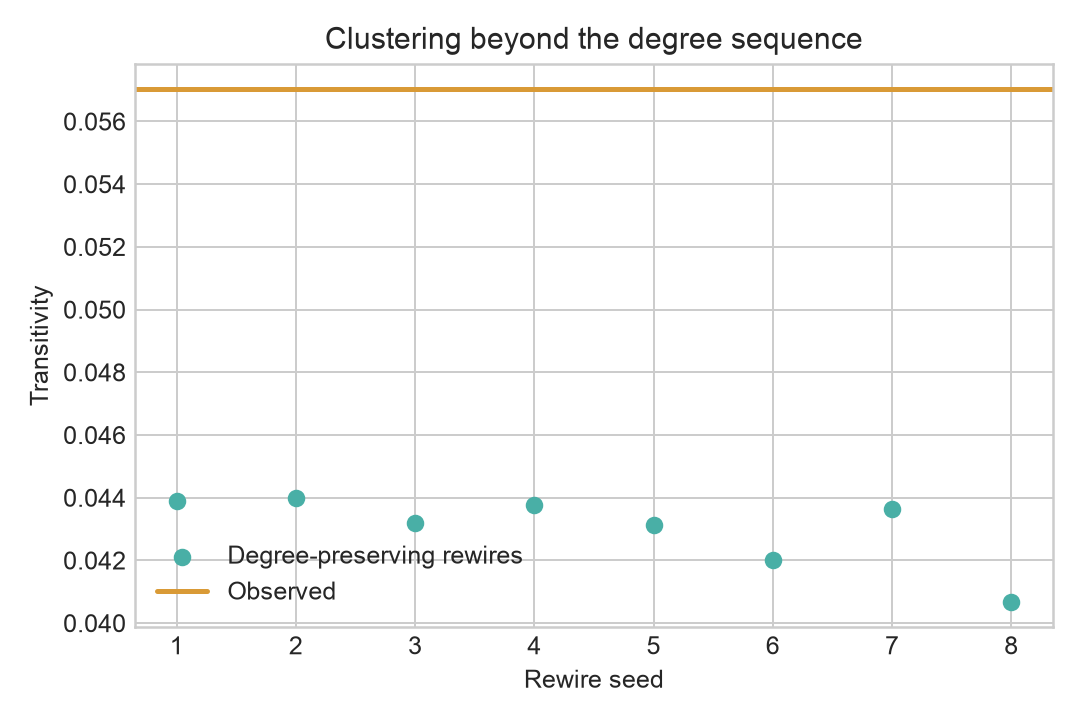

In [4]:
display(rewired.round(4))
Image(filename=str(OUT / 'degree_preserving_null.png'))

### Try it on a small graph

An **invented** graph with two triangles. After ten swaps the links are different, but every node still has the same degree. In this tiny example the new links happen to form two triangles again; on the real network the rewires have clearly lower transitivity.

In [5]:
small = nx.Graph([('A', 'B'), ('B', 'C'), ('C', 'A'), ('C', 'D'),
                  ('D', 'E'), ('E', 'F'), ('F', 'D'), ('A', 'F')])
shuffled = small.copy()
nx.double_edge_swap(shuffled, nswap=10, max_tries=1000, seed=2026)

display(pd.DataFrame({'degree before': dict(small.degree()), 'degree after': dict(shuffled.degree())}))
print('Links before:', sorted(small.edges()))
print('Links after: ', sorted(shuffled.edges()))
print('Transitivity before:', round(nx.transitivity(small), 3), '  after:', round(nx.transitivity(shuffled), 3))

,degree before,degree after
A,3,3
B,2,2
C,3,3
D,3,3
E,2,2
F,3,3


Links before: [('A', 'B'), ('A', 'C'), ('A', 'F'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('D', 'F'), ('E', 'F')]
Links after:  [('A', 'B'), ('A', 'C'), ('A', 'F'), ('B', 'F'), ('C', 'D'), ('C', 'E'), ('D', 'E'), ('D', 'F')]
Transitivity before: 0.429   after: 0.429


## 3. How the shape changed

For each year end we take all positive ratings so far and measure the share of users in the largest component and the transitivity (undirected network), and the **reciprocity**, the share of arrows that are returned (directed network). The users are those seen in a positive rating by then.

,year_end,active_users,directed_positive_ratings,positive_projection_edges,largest_component_share_of_active,projection_transitivity,directed_reciprocity
0,2011,1631,7745,4339,0.9963,0.0460,0.8795
1,2012,3116,16367,9386,0.9981,0.0539,0.8531
2,2013,4991,27505,15890,0.9964,0.0485,0.8446
3,2014,5455,31060,18032,0.9963,0.0549,0.8389
4,2015,5571,31989,18571,0.9961,0.0569,0.8389


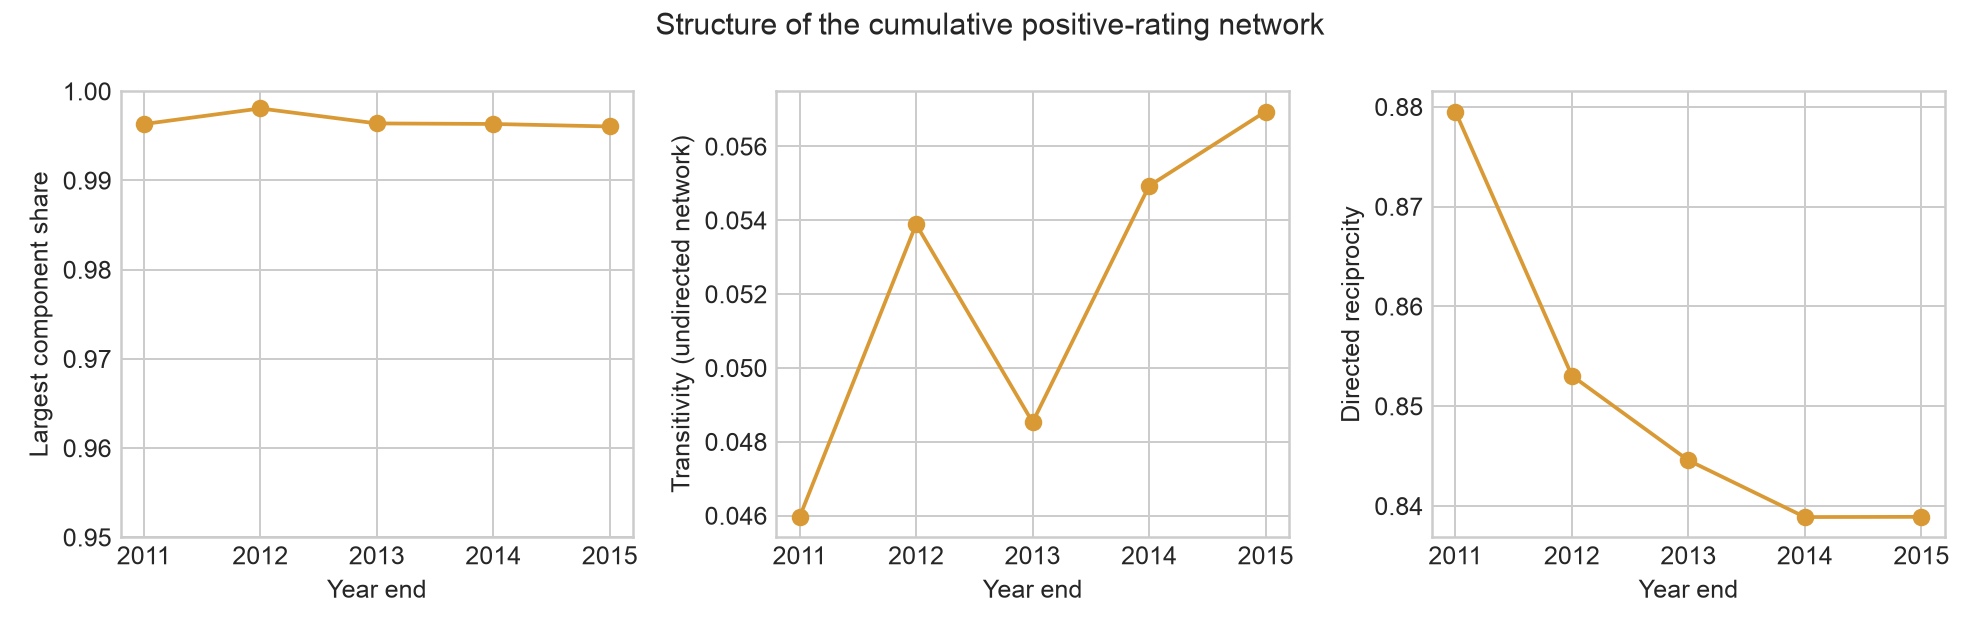

In [6]:
display(evolution.round(4))
Image(filename=str(OUT / 'structural_evolution.png'))

## What we learn

- The real network has more transitivity than all eight rewires, so the degrees alone do not explain all its triangles.
- Reciprocity falls from 0.88 in 2011 to 0.84 in 2015; transitivity rises overall, with a dip in 2013.
- Highly rated users are still chosen more often than similar users, but much less than the simple comparison suggested. This is a comparison, not proof of why raters chose them.